# House Prices — Machine Learning Project

## Objectif
Construire un modèle de régression pour prédire `SalePrice` sur le dataset house-prices-advanced.

**Méthode de travail :** ce notebook est une version pédagogique. Chaque étape sera construite progressivement, avec une cellule de code courte, une vérification, puis une interprétation. Pas de gros bloc de code final dès le début.


 Download dataset from Kaggle


In [ ]:
# ============================================
# 0. DOWNLOAD DATASET FROM KAGGLE
# ============================================

# Install Kaggle API
!pip install -q kaggle

# Upload Kaggle API credentials
from google.colab import files

uploaded = files.upload()

# Configure Kaggle API
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

# Create dataset directory
!mkdir -p /content/house_prices

# Download the Kaggle competition files
!kaggle competitions download \
    -c house-prices-advanced-regression-techniques \
    -p /content/house_prices

# Extract the ZIP file
!unzip -o \
    /content/house_prices/house-prices-advanced-regression-techniques.zip \
    -d /content/house_prices

# Check downloaded files
!ls -lh /content/house_prices

Saving house-prices-advanced-regression-techniques.zip to house-prices-advanced-regression-techniques (1).zip
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication
unzip:  cannot find or open /content/house_prices/house-prices-advanced-regression-techniques.zip, /content/house_prices/house-prices-advanced-regression-techniques.zip.zip or /content/house_prices/house-prices-advanced-regression-techniques.zip.ZIP.
total 944K
-rw-r--r-- 1 root root  14K Dec 15  2019 data_description.txt
-rw-r--r-- 1 root root  32K Dec 15  2019 sample_submission.csv
-rw-r--r-- 1 root root 441K Dec 15  2019 test.csv
-rw-r--r-- 1 root root 450K Dec 15  2019 train.csv


## 1. Imports et environnement

**À faire :** importer uniquement les bibliothèques nécessaires et vérifier les versions si besoin.

In [ ]:
# ============================================
# 1. IMPORTS AND ENVIRONMENT
# ============================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Display options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Check library versions

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.1.3


## 2. Chargement des données

Charger `train.csv` et `test.csv`, puis vérifier :
- dimensions
- premières lignes
- types de variables
- présence de la target dans train uniquement.

In [ ]:
# ============================================
# CHECK KAGGLE DOWNLOAD
# ============================================

import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'house_prices', 'house-prices-advanced-regression-techniques (1).zip', 'house-prices-advanced-regression-techniques.zip', 'sample_data']


In [ ]:
# Check the content of the house_prices folder

print(os.listdir("/content/house_prices"))

['sample_submission.csv', 'train.csv', 'data_description.txt', 'test.csv']


In [ ]:
# ============================================
# EXTRACT KAGGLE DATASET
# ============================================

import os

zip_path = "/content/house-prices-advanced-regression-techniques.zip"
extract_path = "/content/house_prices"

# Extract the ZIP file
!unzip -o "$zip_path" -d "$extract_path"

# Check extracted files
print("\nFiles after extraction:")
print(os.listdir(extract_path))

Archive:  /content/house-prices-advanced-regression-techniques.zip
  inflating: /content/house_prices/data_description.txt  
  inflating: /content/house_prices/sample_submission.csv  
  inflating: /content/house_prices/test.csv  
  inflating: /content/house_prices/train.csv  

Files after extraction:
['sample_submission.csv', 'train.csv', 'data_description.txt', 'test.csv']


In [ ]:
# ============================================
# 2. LOAD DATA
# ============================================

train = pd.read_csv("/content/house_prices/train.csv")
test = pd.read_csv("/content/house_prices/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


## 3. Comprendre le dataset

Avant de nettoyer, comprendre ce que représentent les variables. Utiliser `data_description.txt` lorsque le nom d'une variable n'est pas clair.

In [ ]:
# ============================================
# 3. UNDERSTAND THE DATASET
# ============================================

# Display all column names
print("Training columns:")
print(train.columns.tolist())

Training columns:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'P

In [ ]:
# Check data types

train.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
Street,object
Alley,object
LotShape,object
LandContour,object
Utilities,object


In [ ]:
# Count columns by data type

print("Numerical columns:")
print(train.select_dtypes(include=["int64", "float64"]).shape[1])

print("\nCategorical columns:")
print(train.select_dtypes(include=["object"]).shape[1])

Numerical columns:
38

Categorical columns:
43


## 4. EDA — Target `SalePrice`

Étudier : `describe()`, distribution, skewness, valeurs extrêmes et premières hypothèses.

In [ ]:
# ============================================
# 4. EDA — TARGET: SalePrice
# ============================================

train["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [ ]:
train["SalePrice"].skew()

np.float64(1.8828757597682129)

## 5. EDA — Variables numériques et catégorielles

Explorer les relations avec `SalePrice`, notamment les variables fortement associées. Rappeler : corrélation ≠ causalité et corrélation ≠ feature importance.

In [ ]:
# ============================================
# 5. EDA — NUMERICAL FEATURES
# ============================================

numeric_cols = train.select_dtypes(
    include=["int64", "float64"]
).columns

correlations = train[numeric_cols].corr()["SalePrice"].sort_values(
    ascending=False
)

correlations

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


In [ ]:
# Top numerical correlations with SalePrice

top_corr = correlations.drop("SalePrice").head(10)

top_corr

,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


<Axes: xlabel='OverallQual', ylabel='SalePrice'>

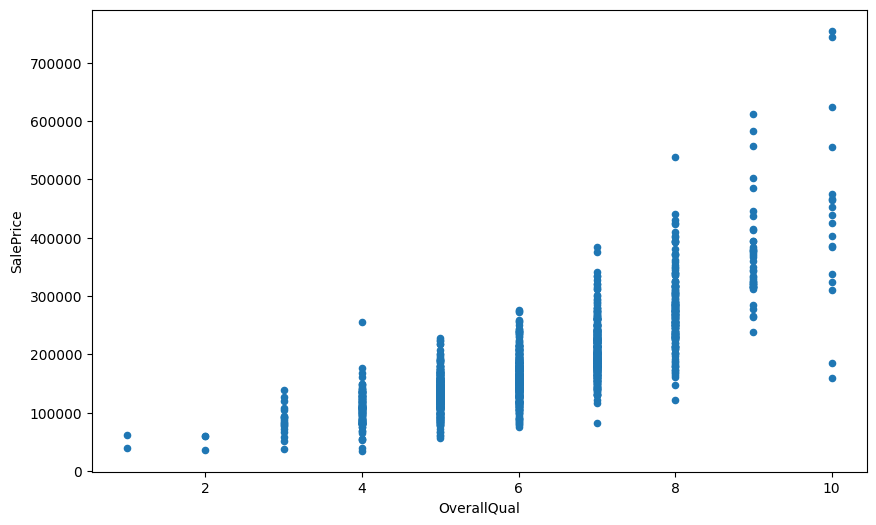

In [ ]:
# Relationship between OverallQual and SalePrice

train.plot(
    x="OverallQual",
    y="SalePrice",
    kind="scatter",
    figsize=(10, 6)
)

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

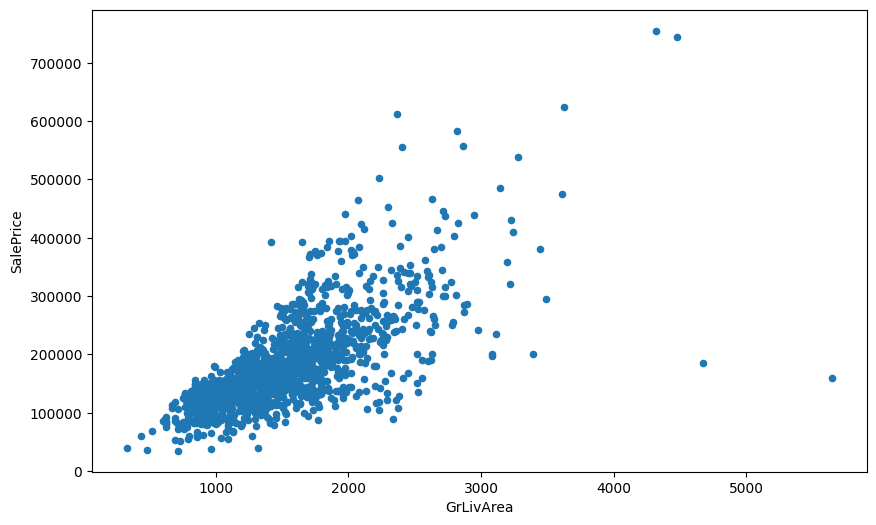

In [ ]:
# Relationship between GrLivArea and SalePrice

train.plot(
    x="GrLivArea",
    y="SalePrice",
    kind="scatter",
    figsize=(10, 6)
)

In [ ]:
# ============================================
# 5. EDA — CATEGORICAL FEATURES
# ============================================

train.groupby("Neighborhood")["SalePrice"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

,count,mean,median
Neighborhood,,,
NoRidge,41,335295.317073,301500.0
NridgHt,77,316270.623377,315000.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Veenker,11,238772.727273,218000.0
Somerst,86,225379.837209,225500.0
ClearCr,28,212565.428571,200250.0
Crawfor,51,210624.725490,200624.0
CollgCr,150,197965.773333,197200.0


In [ ]:
# ============================================
# 5. EDA — CATEGORICAL FEATURES
# ============================================

train.groupby("Neighborhood")["SalePrice"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

,count,mean,median
Neighborhood,,,
NoRidge,41,335295.317073,301500.0
NridgHt,77,316270.623377,315000.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Veenker,11,238772.727273,218000.0
Somerst,86,225379.837209,225500.0
ClearCr,28,212565.428571,200250.0
Crawfor,51,210624.725490,200624.0
CollgCr,150,197965.773333,197200.0


In [ ]:
train.groupby("OverallQual")["SalePrice"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
OverallQual,,,
1,2,50150.000000,50150.0
2,3,51770.333333,60000.0
3,20,87473.750000,86250.0
4,116,108420.655172,108000.0
5,397,133523.347607,133000.0
6,374,161603.034759,160000.0
7,319,207716.423197,200141.0
8,168,274735.535714,269750.0
9,43,367513.023256,345000.0


In [ ]:
# ============================================
# CATEGORICAL FEATURE — Neighborhood
# ============================================

train.groupby("Neighborhood")["SalePrice"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

,count,mean,median
Neighborhood,,,
NoRidge,41,335295.317073,301500.0
NridgHt,77,316270.623377,315000.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Veenker,11,238772.727273,218000.0
Somerst,86,225379.837209,225500.0
ClearCr,28,212565.428571,200250.0
Crawfor,51,210624.725490,200624.0
CollgCr,150,197965.773333,197200.0


In [ ]:
# ============================================
# CATEGORICAL FEATURE — Neighborhood
# ============================================

train.groupby("Neighborhood")["SalePrice"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

,count,mean,median
Neighborhood,,,
NoRidge,41,335295.317073,301500.0
NridgHt,77,316270.623377,315000.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Veenker,11,238772.727273,218000.0
Somerst,86,225379.837209,225500.0
ClearCr,28,212565.428571,200250.0
Crawfor,51,210624.725490,200624.0
CollgCr,150,197965.773333,197200.0


## 6. Missing Values — comprendre avant de remplacer

Principe : `NaN → comprendre la variable → vérifier les variables associées → déterminer le sens → choisir le preprocessing`.

Cas étudiés : Pool, Garage, Basement, Masonry Veneer et vraies valeurs manquantes.

In [ ]:
# ============================================
# 6. MISSING VALUES
# ============================================

missing = train.isnull().sum().sort_values(ascending=False)

missing[missing > 0]

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


In [ ]:
# ============================================
# MISSING VALUES — POOL
# ============================================

print("Missing PoolQC:", train["PoolQC"].isna().sum())
print("Rows with PoolArea = 0:", (train["PoolArea"] == 0).sum())

print("\nPoolArea for rows where PoolQC is missing:")
print(train.loc[train["PoolQC"].isna(), "PoolArea"].value_counts().sort_index())

Missing PoolQC: 1453
Rows with PoolArea = 0: 1453

PoolArea for rows where PoolQC is missing:
PoolArea
0    1453
Name: count, dtype: int64


In [ ]:
# ============================================
# MISSING VALUES — GARAGE
# ============================================

garage_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "GarageYrBlt"
]

print("Rows with missing GarageType:")
print(train["GarageType"].isna().sum())

print("\nGarageArea for rows with missing GarageType:")
print(
    train.loc[
        train["GarageType"].isna(),
        "GarageArea"
    ].value_counts().sort_index()
)

Rows with missing GarageType:
81

GarageArea for rows with missing GarageType:
GarageArea
0    81
Name: count, dtype: int64


In [ ]:
# ============================================
# MISSING VALUES — BASEMENT
# ============================================

basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

print("Missing BsmtQual:", train["BsmtQual"].isna().sum())

print("\nTotalBsmtSF for rows with missing BsmtQual:")
print(
    train.loc[
        train["BsmtQual"].isna(),
        "TotalBsmtSF"
    ].value_counts().sort_index()
)

Missing BsmtQual: 37

TotalBsmtSF for rows with missing BsmtQual:
TotalBsmtSF
0    37
Name: count, dtype: int64


In [ ]:
# Investigate the extra missing BsmtFinType2

train.loc[
    train["BsmtFinType2"].isna() &
    train["BsmtQual"].notna(),
    [
        "Id",
        "BsmtQual",
        "BsmtFinType1",
        "BsmtFinType2",
        "BsmtFinSF1",
        "BsmtFinSF2",
        "TotalBsmtSF"
    ]
]

,Id,BsmtQual,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,TotalBsmtSF
332,333,Gd,GLQ,NaN,1124,479,3206


In [ ]:
train.loc[
    train["BsmtFinType1"] == "GLQ",
    "BsmtFinType2"
].value_counts(dropna=False)

,count
BsmtFinType2,
Unf,392
LwQ,10
Rec,9
ALQ,4
BLQ,2
NaN,1


In [ ]:
train.loc[
    train["BsmtFinType2"].isna() &
    train["BsmtQual"].notna(),
    "BsmtFinType2"
] = "Unf"

In [ ]:
print("Missing BsmtFinType2:", train["BsmtFinType2"].isna().sum())

Missing BsmtFinType2: 37


Un NaN n'a pas toujours la même signification.
Il faut d'abord comprendre le sens métier de la variable avant de choisir la stratégie d'imputation.


In [ ]:
basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

train.loc[
    train["TotalBsmtSF"] == 0,
    basement_cols
] = "None"

In [ ]:
print(train[basement_cols].isnull().sum())

BsmtQual        0
BsmtCond        0
BsmtExposure    1
BsmtFinType1    0
BsmtFinType2    0
dtype: int64


In [ ]:
train.loc[
    train["BsmtExposure"].isna(),
    [
        "Id",
        "BsmtQual",
        "BsmtCond",
        "BsmtExposure",
        "BsmtFinType1",
        "BsmtFinType2",
        "BsmtFinSF1",
        "BsmtFinSF2",
        "BsmtUnfSF",
        "TotalBsmtSF"
    ]
]

,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF
948,949,Gd,TA,NaN,Unf,Unf,0,0,936,936


In [ ]:
train.loc[
    (train["BsmtFinType1"] == "Unf") &
    (train["BsmtFinType2"] == "Unf"),
    "BsmtExposure"
].value_counts(dropna=False)

,count
BsmtExposure,
No,345
Av,46
Mn,27
Gd,11
NaN,1


In [ ]:
train.loc[
    train["BsmtExposure"].isna(),
    "BsmtExposure"
] = "No"

In [ ]:
print(train[basement_cols].isnull().sum())

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64


In [ ]:
masvnr_cols = ["MasVnrType", "MasVnrArea"]

print("Missing MasVnrType:", train["MasVnrType"].isna().sum())
print("Missing MasVnrArea:", train["MasVnrArea"].isna().sum())

print("\nMasVnrArea for missing MasVnrType:")
print(
    train.loc[
        train["MasVnrType"].isna(),
        "MasVnrArea"
    ].value_counts(dropna=False).sort_index()
)

Missing MasVnrType: 872
Missing MasVnrArea: 8

MasVnrArea for missing MasVnrType:
MasVnrArea
0.0      859
1.0        2
288.0      1
312.0      1
344.0      1
NaN        8
Name: count, dtype: int64


In [ ]:
train.loc[
    train["MasVnrType"].isna() &
    train["MasVnrArea"].gt(0),
    [
        "Id",
        "MasVnrType",
        "MasVnrArea",
        "OverallQual",
        "Neighborhood",
        "YearBuilt",
        "Exterior1st",
        "Exterior2nd"
    ]
]

,Id,MasVnrType,MasVnrArea,OverallQual,Neighborhood,YearBuilt,Exterior1st,Exterior2nd
624,625,NaN,288.0,6,NWAmes,1972,VinylSd,VinylSd
773,774,NaN,1.0,5,NAmes,1958,Wd Sdng,Wd Sdng
1230,1231,NaN,1.0,5,Sawyer,1977,Plywood,Plywood
1300,1301,NaN,344.0,7,Gilbert,1999,VinylSd,VinylSd
1334,1335,NaN,312.0,5,BrDale,1970,HdBoard,HdBoard


In [ ]:
train.loc[
    train["MasVnrType"].isna() &
    train["MasVnrArea"].gt(0),
    [
        "Id",
        "MasVnrArea",
        "OverallQual",
        "Neighborhood",
        "YearBuilt",
        "Exterior1st",
        "Exterior2nd",
        "Foundation",
        "SalePrice"
    ]
]

,Id,MasVnrArea,OverallQual,Neighborhood,YearBuilt,Exterior1st,Exterior2nd,Foundation,SalePrice
624,625,288.0,6,NWAmes,1972,VinylSd,VinylSd,CBlock,165150
773,774,1.0,5,NAmes,1958,Wd Sdng,Wd Sdng,CBlock,114500
1230,1231,1.0,5,Sawyer,1977,Plywood,Plywood,CBlock,190000
1300,1301,344.0,7,Gilbert,1999,VinylSd,VinylSd,PConc,225000
1334,1335,312.0,5,BrDale,1970,HdBoard,HdBoard,CBlock,125000


In [ ]:
missing_masonry = train[
    train["MasVnrType"].isna() &
    train["MasVnrArea"].isna()
]

missing_masonry[
    [
        "Id",
        "OverallQual",
        "Neighborhood",
        "YearBuilt",
        "Exterior1st",
        "Exterior2nd",
        "Foundation",
        "SalePrice"
    ]
]

,Id,OverallQual,Neighborhood,YearBuilt,Exterior1st,Exterior2nd,Foundation,SalePrice
234,235,6,Gilbert,2002,VinylSd,VinylSd,PConc,216500
529,530,6,Crawfor,1957,Wd Sdng,Stone,PConc,200624
650,651,7,Somerst,2007,CemntBd,CmentBd,PConc,205950
936,937,7,SawyerW,2003,VinylSd,VinylSd,PConc,184900
973,974,7,Somerst,2007,CemntBd,CmentBd,PConc,182000
977,978,7,Somerst,2006,VinylSd,VinylSd,PConc,199900
1243,1244,10,NridgHt,2006,VinylSd,VinylSd,PConc,465000
1278,1279,8,CollgCr,2002,VinylSd,VinylSd,PConc,237000


In [ ]:
# Handle Masonry Veneer missing values

# No veneer: area is explicitly zero
train.loc[
    train["MasVnrArea"] == 0,
    "MasVnrType"
] = "None"

# Missing type: use "None" as the missing category
train["MasVnrType"] = train["MasVnrType"].fillna("None")

# Missing area with missing type -> no veneer
train["MasVnrArea"] = train["MasVnrArea"].fillna(0)

In [ ]:
print("Missing MasVnrType:", train["MasVnrType"].isna().sum())
print("Missing MasVnrArea:", train["MasVnrArea"].isna().sum())

Missing MasVnrType: 0
Missing MasVnrArea: 0


In [ ]:
print("Missing FireplaceQu:", train["FireplaceQu"].isna().sum())
print("Rows with Fireplaces = 0:", (train["Fireplaces"] == 0).sum())

print(
    train.loc[
        train["FireplaceQu"].isna(),
        "Fireplaces"
    ].value_counts().sort_index()
)

Missing FireplaceQu: 690
Rows with Fireplaces = 0: 690
Fireplaces
0    690
Name: count, dtype: int64


In [ ]:
train.loc[
    train["Fireplaces"] == 0,
    "FireplaceQu"
] = "None"

In [ ]:
print("Missing FireplaceQu:", train["FireplaceQu"].isna().sum())

Missing FireplaceQu: 0


In [ ]:
train.loc[
    train["LotFrontage"].isna(),
    ["Id", "Neighborhood", "LotArea", "LotFrontage"]
].head(20)

,Id,Neighborhood,LotArea,LotFrontage
7,8,NWAmes,10382,NaN
12,13,Sawyer,12968,NaN
14,15,NAmes,10920,NaN
16,17,NAmes,11241,NaN
24,25,Sawyer,8246,NaN
31,32,Sawyer,8544,NaN
42,43,SawyerW,9180,NaN
43,44,CollgCr,9200,NaN
50,51,Gilbert,13869,NaN
64,65,CollgCr,9375,NaN


In [ ]:
train.groupby("Neighborhood")["LotFrontage"].agg(
    ["count", "mean", "median"]
).sort_values("count", ascending=False)

,count,mean,median
Neighborhood,,,
NAmes,186,76.462366,73.0
CollgCr,126,71.682540,70.0
OldTown,109,62.788991,60.0
Edwards,92,68.217391,65.5
Somerst,78,64.666667,73.5
NridgHt,76,81.881579,88.5
BrkSide,51,57.509804,52.0
SawyerW,50,71.500000,66.5
Gilbert,49,79.877551,65.0


In [ ]:
train["LotFrontage"] = train.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

In [ ]:
print("Missing LotFrontage:", train["LotFrontage"].isna().sum())

Missing LotFrontage: 0


In [ ]:
garage_cat_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

train.loc[
    train["GarageArea"] == 0,
    garage_cat_cols
] = "None"

In [ ]:
print(train[garage_cat_cols].isna().sum())
print("Missing GarageYrBlt:", train["GarageYrBlt"].isna().sum())

GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
dtype: int64
Missing GarageYrBlt: 81


In [ ]:
basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

print("Missing BsmtQual:", train["BsmtQual"].isna().sum())

print(
    train.loc[
        train["BsmtQual"].isna(),
        "TotalBsmtSF"
    ].value_counts().sort_index()
)

Missing BsmtQual: 0
Series([], Name: count, dtype: int64)


In [ ]:
basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

train[basement_cols].isna().sum()

,0
BsmtQual,0
BsmtCond,0
BsmtExposure,0
BsmtFinType1,0
BsmtFinType2,0


In [ ]:
missing = train.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
GarageYrBlt,81
Electrical,1


In [ ]:
print("Missing MiscFeature:", train["MiscFeature"].isna().sum())

print(
    train.loc[
        train["MiscFeature"].isna(),
        "MiscVal"
    ].value_counts().sort_index()
)

Missing MiscFeature: 1406
MiscVal
0    1406
Name: count, dtype: int64


In [ ]:
train["MiscFeature"] = train["MiscFeature"].fillna("None")

In [ ]:
print("Missing MiscFeature:", train["MiscFeature"].isna().sum())

Missing MiscFeature: 0


In [ ]:
print("Missing Alley:", train["Alley"].isna().sum())

print(
    train.loc[
        train["Alley"].isna(),
        ["Alley", "LotShape", "LotConfig", "LotArea"]
    ].head(20)
)

Missing Alley: 1369
   Alley LotShape LotConfig  LotArea
0    NaN      Reg    Inside     8450
1    NaN      Reg       FR2     9600
2    NaN      IR1    Inside    11250
3    NaN      IR1    Corner     9550
4    NaN      IR1       FR2    14260
5    NaN      IR1    Inside    14115
6    NaN      Reg    Inside    10084
7    NaN      IR1    Corner    10382
8    NaN      Reg    Inside     6120
9    NaN      Reg    Corner     7420
10   NaN      Reg    Inside    11200
11   NaN      IR1    Inside    11924
12   NaN      IR2    Inside    12968
13   NaN      IR1    Inside    10652
14   NaN      IR1    Corner    10920
15   NaN      Reg    Corner     6120
16   NaN      IR1   CulDSac    11241
17   NaN      Reg    Inside    10791
18   NaN      Reg    Inside    13695
19   NaN      Reg    Inside     7560


In [ ]:
train["Alley"] = train["Alley"].fillna("None")

In [ ]:
print("Missing Alley:", train["Alley"].isna().sum())

Missing Alley: 0


In [ ]:
print("Missing Fence:", train["Fence"].isna().sum())

print(
    train.loc[
        train["Fence"].isna(),
        ["Fence", "LotArea", "Neighborhood", "OverallQual"]
    ].head(20)
)

Missing Fence: 1179
   Fence  LotArea Neighborhood  OverallQual
0    NaN     8450      CollgCr            7
1    NaN     9600      Veenker            6
2    NaN    11250      CollgCr            7
3    NaN     9550      Crawfor            7
4    NaN    14260      NoRidge            8
6    NaN    10084      Somerst            8
7    NaN    10382       NWAmes            7
8    NaN     6120      OldTown            7
9    NaN     7420      BrkSide            5
10   NaN    11200       Sawyer            5
11   NaN    11924      NridgHt            9
12   NaN    12968       Sawyer            5
13   NaN    10652      CollgCr            7
16   NaN    11241        NAmes            6
17   NaN    10791       Sawyer            4
18   NaN    13695      SawyerW            5
20   NaN    14215      NridgHt            8
22   NaN     9742      CollgCr            8
23   NaN     4224      MeadowV            5
25   NaN    14230      NridgHt            8


In [ ]:
train["Fence"] = train["Fence"].fillna("None")

In [ ]:
print("Missing Fence:", train["Fence"].isna().sum())

Missing Fence: 0


In [ ]:
train.loc[
    train["GarageArea"] == 0,
    "GarageYrBlt"
] = 0

In [ ]:
print("Missing GarageYrBlt:", train["GarageYrBlt"].isna().sum())

Missing GarageYrBlt: 0


In [ ]:
train.loc[
    train["Electrical"].isna(),
    [
        "Id",
        "Electrical",
        "Neighborhood",
        "OverallQual",
        "YearBuilt",
        "SalePrice"
    ]
]

,Id,Electrical,Neighborhood,OverallQual,YearBuilt,SalePrice
1379,1380,NaN,Timber,5,2006,167500


In [ ]:
train["Electrical"].value_counts()

,count
Electrical,
SBrkr,1334
FuseA,94
FuseF,27
FuseP,3
Mix,1


In [ ]:
train.groupby("Electrical")["YearBuilt"].agg(
    ["count", "min", "max", "mean", "median"]
).sort_values("median")

,count,min,max,mean,median
Electrical,,,,,
Mix,1,1920,1920,1920.000000,1920.0
FuseP,3,1910,1955,1930.000000,1925.0
FuseF,27,1910,1965,1936.259259,1940.0
FuseA,94,1880,1960,1937.904255,1941.0
SBrkr,1334,1872,2010,1974.432534,1977.0


In [ ]:
train.loc[
    train["YearBuilt"].between(2000, 2010),
    ["YearBuilt", "Electrical"]
].value_counts().sort_index()

,,count
YearBuilt,Electrical,
2000,SBrkr,24
2001,SBrkr,20
2002,SBrkr,23
2003,SBrkr,45
2004,SBrkr,54
2005,SBrkr,64
2006,SBrkr,66
2007,SBrkr,49
2008,SBrkr,23


In [ ]:
train.loc[
    train["Electrical"].isna(),
    "Electrical"
] = "SBrkr"

In [ ]:
print("Missing Electrical:", train["Electrical"].isna().sum())

Missing Electrical: 0


In [ ]:
missing = train.isnull().sum().sort_values(ascending=False)

missing[missing > 0]

,0
PoolQC,1453


In [ ]:
train.loc[
    train["PoolArea"] == 0,
    "PoolQC"
] = "None"


In [ ]:
missing = train.isnull().sum().sort_values(ascending=False)

print(missing[missing > 0])
print("\nTotal missing values:", train.isnull().sum().sum())

Series([], dtype: int64)

Total missing values: 0


## 7. Preprocessing

Classifier les variables : numériques, nominales, ordinales/binaire. Appliquer les transformations progressivement et vérifier le résultat après chaque étape.

In [ ]:
X = train.drop("SalePrice", axis=1).copy()
y = train["SalePrice"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1460, 80)
y shape: (1460,)


In [ ]:
X[ordinal_cols].head()

,LotShape,LandSlope,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,HeatingQC,KitchenQual,FireplaceQu,GarageFinish,GarageQual,GarageCond,PoolQC
0,Reg,Gtl,Gd,TA,Gd,TA,No,GLQ,Unf,Ex,Gd,None,RFn,TA,TA,None
1,Reg,Gtl,TA,TA,Gd,TA,Gd,ALQ,Unf,Ex,TA,TA,RFn,TA,TA,None
2,IR1,Gtl,Gd,TA,Gd,TA,Mn,GLQ,Unf,Ex,Gd,TA,RFn,TA,TA,None
3,IR1,Gtl,TA,TA,TA,Gd,No,ALQ,Unf,Gd,Gd,Gd,Unf,TA,TA,None
4,IR1,Gtl,Gd,TA,Gd,TA,Av,GLQ,Unf,Ex,Gd,TA,RFn,TA,TA,None


In [ ]:
# Apply ordinal encoding

for col, mapping in ordinal_mappings.items():
    X[col] = X[col].map(mapping)

X[ordinal_cols].head()

,LotShape,LandSlope,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,HeatingQC,KitchenQual,FireplaceQu,GarageFinish,GarageQual,GarageCond,PoolQC
0,3,2,3,2,4,3,1,6,1,4,3,0,2,3,3,0
1,3,2,2,2,4,3,4,5,1,4,2,3,2,3,3,0
2,2,2,3,2,4,3,2,6,1,4,3,3,2,3,3,0
3,2,2,2,2,3,4,1,5,1,3,3,4,1,3,3,0
4,2,2,3,2,4,3,3,6,1,4,3,3,2,3,3,0


In [ ]:
# Apply one-hot encoding to nominal features

X = pd.get_dummies(
    X,
    columns=nominal_cols,
    drop_first=False,
    dtype=int
)

print("X shape after encoding:", X.shape)

X shape after encoding: (1460, 239)


In [ ]:
# Final preprocessing checks

print("X shape:", X.shape)
print("Total missing values:", X.isnull().sum().sum())
print("Remaining object columns:", X.select_dtypes(include="object").columns.tolist())

X shape: (1460, 239)
Total missing values: 0
Remaining object columns: []


## 8. Train / validation split

Séparer `X` et `y`, puis créer un jeu d'entraînement et un jeu de validation. Expliquer pourquoi on ne doit pas utiliser le test Kaggle pour choisir le modèle.

In [ ]:
# Split the data into training and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (1168, 239)
X_val: (292, 239)
y_train: (1168,)
y_val: (292,)


In [ ]:
# Baseline: predict the mean SalePrice

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

baseline_prediction = np.full(
    shape=len(y_val),
    fill_value=y_train.mean()
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_prediction)
)

baseline_mae = mean_absolute_error(
    y_val,
    baseline_prediction
)

baseline_r2 = r2_score(
    y_val,
    baseline_prediction
)

print("Baseline RMSE:", baseline_rmse)
print("Baseline MAE:", baseline_mae)
print("Baseline R²:", baseline_r2)

Baseline RMSE: 87619.03450611533
Baseline MAE: 62575.926451960964
Baseline R²: -0.0008824918802490256


In [ ]:
from sklearn.linear_model import LinearRegression

# Create and train the model
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Predictions on validation set
y_pred_linear = linear_model.predict(X_val)

# Evaluation
linear_rmse = np.sqrt(mean_squared_error(y_val, y_pred_linear))
linear_mae = mean_absolute_error(y_val, y_pred_linear)
linear_r2 = r2_score(y_val, y_pred_linear)

print("Linear Regression")
print("-----------------")
print("RMSE:", linear_rmse)
print("MAE :", linear_mae)
print("R²  :", linear_r2)

Linear Regression
-----------------
RMSE: 30797.3381852476
MAE : 20102.090530110825
R²  : 0.8763447585308974


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create and train the model
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_val)

# Evaluation
rf_rmse = np.sqrt(mean_squared_error(y_val, y_pred_rf))
rf_mae = mean_absolute_error(y_val, y_pred_rf)
rf_r2 = r2_score(y_val, y_pred_rf)

print("Random Forest")
print("-------------")
print("RMSE:", rf_rmse)
print("MAE :", rf_mae)
print("R²  :", rf_r2)

Random Forest
-------------
RMSE: 28660.01813653906
MAE : 17325.673002283103
R²  : 0.8929124241395241


### 9. Cross-validation

Comparer la performance moyenne et la variabilité entre les folds. Chercher à comprendre les folds difficiles plutôt que supprimer automatiquement les observations.

In [ ]:
from sklearn.model_selection import cross_val_score

rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

rf_cv_rmse = -rf_cv_scores

print("Random Forest - 5-Fold Cross-Validation")
print("-----------------------------------------")
print("RMSE scores:", rf_cv_rmse)
print("Mean RMSE:", rf_cv_rmse.mean())
print("Std RMSE :", rf_cv_rmse.std())

Random Forest - 5-Fold Cross-Validation
-----------------------------------------
RMSE scores: [29909.83043023 35637.04257308 36417.58075954 25346.82216398
 25511.79970649]
Mean RMSE: 30564.61512666386
Std RMSE : 4757.557713138324


In [ ]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold, (_, val_idx) in enumerate(kf.split(X_train), start=1):
    y_fold = y_train.iloc[val_idx]

    print(f"Fold {fold}")
    print("  Size   :", len(y_fold))
    print("  Mean   :", y_fold.mean())
    print("  Median :", y_fold.median())
    print("  Min    :", y_fold.min())
    print("  Max    :", y_fold.max())
    print()

Fold 1
  Size   : 234
  Mean   : 183066.06837606838
  Median : 167500.0
  Min    : 55000
  Max    : 625000

Fold 2
  Size   : 234
  Mean   : 178861.20512820513
  Median : 157250.0
  Min    : 60000
  Max    : 582933

Fold 3
  Size   : 234
  Mean   : 185516.2393162393
  Median : 169000.0
  Min    : 34900
  Max    : 745000

Fold 4
  Size   : 233
  Mean   : 179002.96566523606
  Median : 167500.0
  Min    : 52500
  Max    : 555000

Fold 5
  Size   : 233
  Mean   : 180747.84549356223
  Median : 164500.0
  Min    : 52000
  Max    : 538000



In [ ]:
error_analysis = pd.DataFrame({
    "Actual": y_val,
    "Predicted": y_pred_rf
})

error_analysis["Residual"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

error_analysis["AbsoluteError"] = (
    error_analysis["Residual"].abs()
)

error_analysis = error_analysis.sort_values(
    "AbsoluteError",
    ascending=False
)

error_analysis.head(10)

,Actual,Predicted,Residual,AbsoluteError
691,755000,573099.206667,181900.793333,181900.793333
898,611657,447473.976667,164183.023333,164183.023333
1046,556581,417360.570000,139220.430000,139220.430000
581,253293,369937.633333,-116644.633333,116644.633333
218,311500,210506.873333,100993.126667,100993.126667
774,395000,308200.876667,86799.123333,86799.123333
1243,465000,380501.650000,84498.350000,84498.350000
231,403000,333652.766667,69347.233333,69347.233333
196,311872,246292.163333,65579.836667,65579.836667
1024,287000,348410.023333,-61410.023333,61410.023333


In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_val)

xgb_rmse = np.sqrt(mean_squared_error(y_val, y_pred_xgb))
xgb_mae = mean_absolute_error(y_val, y_pred_xgb)
xgb_r2 = r2_score(y_val, y_pred_xgb)

print("XGBoost Regression")
print("------------------")
print("RMSE:", xgb_rmse)
print("MAE :", xgb_mae)
print("R²  :", xgb_r2)

XGBoost Regression
------------------
RMSE: 25685.971891287274
MAE : 16243.8427734375
R²  : 0.9139842391014099


In [ ]:
from sklearn.model_selection import cross_validate

xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    n_jobs=-1,
    return_train_score=False
)

xgb_cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "RMSE": -xgb_cv["test_rmse"],
    "MAE": -xgb_cv["test_mae"],
    "R2": xgb_cv["test_r2"]
})

xgb_cv_results

,Fold,RMSE,MAE,R2
0,1,30700.896484,15727.176758,0.861457
1,2,34574.167969,17504.697266,0.773606
2,3,30909.646484,17522.671875,0.868889
3,4,23531.849609,15926.131836,0.896574
4,5,22119.371094,13503.530273,0.902621


In [ ]:
cv_summary = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R²"],
    "Mean": [
        xgb_cv_results["RMSE"].mean(),
        xgb_cv_results["MAE"].mean(),
        xgb_cv_results["R2"].mean()
    ],
    "Std": [
        xgb_cv_results["RMSE"].std(),
        xgb_cv_results["MAE"].std(),
        xgb_cv_results["R2"].std()
    ]
})

cv_summary

,Metric,Mean,Std
0,RMSE,28367.186328,5311.605318
1,MAE,16036.841602,1649.856593
2,R²,0.860629,0.051714


La cross-validation montre que XGBoost obtient un RMSE moyen de 28 367 ± 5 312 et un R² moyen de 0.861 ± 0.052 sur 5 folds. Les performances varient sensiblement selon le fold, avec un fold particulièrement difficile (Fold 2, R² = 0.774). Cette variabilité suggère que la difficulté dépend de la composition des données de validation et justifie une analyse des erreurs plutôt que la suppression automatique des observations.


## 10. Outliers et error analysis

Étudier les erreurs importantes et vérifier si les observations extrêmes sont réellement des erreurs de données. Analyser les résidus et le comportement du modèle sur les maisons très chères et très peu chères.

In [ ]:
error_analysis = pd.DataFrame({
    "Actual": y_val,
    "Predicted": y_pred_xgb
})

error_analysis["Residual"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

error_analysis["AbsoluteError"] = (
    error_analysis["Residual"].abs()
)

error_analysis = error_analysis.sort_values(
    "AbsoluteError",
    ascending=False
)

error_analysis.head(10)

,Actual,Predicted,Residual,AbsoluteError
898,611657,462735.437500,148921.562500,148921.562500
691,755000,610366.062500,144633.937500,144633.937500
581,253293,366916.250000,-113623.250000,113623.250000
1046,556581,462279.906250,94301.093750,94301.093750
774,395000,310328.156250,84671.843750,84671.843750
218,311500,227931.265625,83568.734375,83568.734375
261,276000,358350.656250,-82350.656250,82350.656250
588,143000,214703.171875,-71703.171875,71703.171875
1024,287000,358486.562500,-71486.562500,71486.562500
607,225000,157085.234375,67914.765625,67914.765625


In [ ]:
error_indices = error_analysis.head(10).index

error_houses = train.loc[
    error_indices,
    [
        "SalePrice",
        "OverallQual",
        "GrLivArea",
        "GarageCars",
        "GarageArea",
        "TotalBsmtSF",
        "1stFlrSF",
        "YearBuilt",
        "YearRemodAdd",
        "Neighborhood"
    ]
].copy()

error_houses

,SalePrice,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,YearBuilt,YearRemodAdd,Neighborhood
898,611657,9,2364,3,820,2330,2364,2009,2010,NridgHt
691,755000,10,4316,3,832,2444,2444,1994,1995,NoRidge
581,253293,8,2042,3,1390,2042,2042,2008,2009,NridgHt
1046,556581,9,2868,3,716,1992,1992,2005,2006,StoneBr
774,395000,8,1973,3,895,1935,1973,2006,2006,NridgHt
218,311500,7,1954,2,431,798,1137,1939,2006,Crawfor
261,276000,8,2574,3,868,1482,1482,2007,2007,CollgCr
588,143000,5,1473,1,452,1437,1473,1968,2003,ClearCr
1024,287000,8,2898,2,665,1565,2898,1976,1976,Timber
607,225000,5,2008,1,230,896,1112,1948,2002,Edwards


In [ ]:
print("Residual statistics")
print("-------------------")
print(error_analysis["Residual"].describe())

print("\nAbsolute error statistics")
print("-------------------------")
print(error_analysis["AbsoluteError"].describe())

Residual statistics
-------------------
count       292.000000
mean        -26.611756
std       25730.053947
min     -113623.250000
25%      -10420.554688
50%         594.570312
75%        9995.507812
max      148921.562500
Name: Residual, dtype: float64

Absolute error statistics
-------------------------
count       292.000000
mean      16243.840941
std       19931.564783
min         121.578125
25%        4990.962891
50%       10127.390625
75%       18726.169922
max      148921.562500
Name: AbsoluteError, dtype: float64


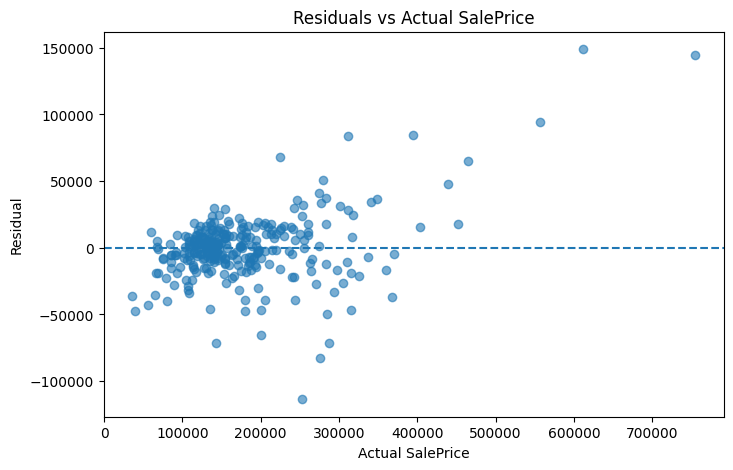

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    error_analysis["Actual"],
    error_analysis["Residual"],
    alpha=0.6
)

plt.axhline(0, linestyle="--")

plt.xlabel("Actual SalePrice")
plt.ylabel("Residual")
plt.title("Residuals vs Actual SalePrice")

plt.show()

Les erreurs augmentent avec le prix des maisons. Le modèle sous-estime particulièrement certaines maisons très chères. Les observations extrêmes semblent être de vraies observations plutôt que des erreurs évidentes de données, donc leur suppression automatique n'est pas justifiée.



In [ ]:
error_analysis["PriceGroup"] = pd.cut(
    error_analysis["Actual"],
    bins=[0, 100000, 200000, 300000, 400000, 500000, np.inf],
    labels=[
        "<100k",
        "100k-200k",
        "200k-300k",
        "300k-400k",
        "400k-500k",
        ">500k"
    ]
)

price_error_analysis = (
    error_analysis
    .groupby("PriceGroup", observed=False)
    .agg(
        Count=("Actual", "size"),
        RMSE=("Residual", lambda x: np.sqrt(np.mean(x**2))),
        MAE=("AbsoluteError", "mean")
    )
    .reset_index()
)

price_error_analysis

,PriceGroup,Count,RMSE,MAE
0,<100k,26,21239.907951,16210.335938
1,100k-200k,184,14187.997639,10342.615786
2,200k-300k,58,32218.339759,23519.796875
3,300k-400k,17,38060.101784,30617.991728
4,400k-500k,4,42023.168054,36545.210938
5,>500k,3,131642.576619,129285.531250


## 11. Feature engineering

Tester une feature à la fois. Dans le premier projet : `TotalSF`, `TotalPorchSF`, `HouseAge`, `RemodAge`.

Comparer chaque ajout avec une validation identique avant de le conserver.

In [ ]:
X_total_sf = X.copy()

X_total_sf["TotalSF"] = (
    X_total_sf["TotalBsmtSF"]
    + X_total_sf["1stFlrSF"]
    + X_total_sf["2ndFlrSF"]
)

print("Original X shape:", X.shape)
print("New X shape:", X_total_sf.shape)

X_total_sf[["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "TotalSF"]].head()

Original X shape: (1460, 239)
New X shape: (1460, 240)


,TotalBsmtSF,1stFlrSF,2ndFlrSF,TotalSF
0,856,856,854,2566
1,1262,1262,0,2524
2,920,920,866,2706
3,756,961,756,2473
4,1145,1145,1053,3343


In [ ]:
X_train_sf, X_val_sf, y_train_sf, y_val_sf = train_test_split(
    X_total_sf,
    y,
    test_size=0.2,
    random_state=42
)

xgb_total_sf = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_total_sf.fit(X_train_sf, y_train_sf)

y_pred_total_sf = xgb_total_sf.predict(X_val_sf)

total_sf_rmse = np.sqrt(
    mean_squared_error(y_val_sf, y_pred_total_sf)
)

total_sf_mae = mean_absolute_error(
    y_val_sf, y_pred_total_sf
)

total_sf_r2 = r2_score(
    y_val_sf, y_pred_total_sf
)

print("XGBoost + TotalSF")
print("-----------------")
print("RMSE:", total_sf_rmse)
print("MAE :", total_sf_mae)
print("R²  :", total_sf_r2)

XGBoost + TotalSF
-----------------
RMSE: 26600.17924751636
MAE : 16239.3955078125
R²  : 0.9077523350715637


In [ ]:
X_total_porch = X.copy()

X_total_porch["TotalPorchSF"] = (
    X_total_porch["OpenPorchSF"]
    + X_total_porch["3SsnPorch"]
    + X_total_porch["EnclosedPorch"]
    + X_total_porch["ScreenPorch"]
    + X_total_porch["WoodDeckSF"]
)

print("Original X shape:", X.shape)
print("New X shape:", X_total_porch.shape)

X_total_porch[
    [
        "OpenPorchSF",
        "3SsnPorch",
        "EnclosedPorch",
        "ScreenPorch",
        "WoodDeckSF",
        "TotalPorchSF"
    ]
].head()

Original X shape: (1460, 239)
New X shape: (1460, 240)


,OpenPorchSF,3SsnPorch,EnclosedPorch,ScreenPorch,WoodDeckSF,TotalPorchSF
0,61,0,0,0,0,61
1,0,0,0,0,298,298
2,42,0,0,0,0,42
3,35,0,272,0,0,307
4,84,0,0,0,192,276


In [ ]:
X_train_porch, X_val_porch, y_train_porch, y_val_porch = train_test_split(
    X_total_porch,
    y,
    test_size=0.2,
    random_state=42
)

xgb_total_porch = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_total_porch.fit(X_train_porch, y_train_porch)

y_pred_total_porch = xgb_total_porch.predict(X_val_porch)

total_porch_rmse = np.sqrt(
    mean_squared_error(y_val_porch, y_pred_total_porch)
)

total_porch_mae = mean_absolute_error(
    y_val_porch, y_pred_total_porch
)

total_porch_r2 = r2_score(
    y_val_porch, y_pred_total_porch
)

print("XGBoost + TotalPorchSF")
print("---------------------")
print("RMSE:", total_porch_rmse)
print("MAE :", total_porch_mae)
print("R²  :", total_porch_r2)

XGBoost + TotalPorchSF
---------------------
RMSE: 25343.387618864217
MAE : 16084.1572265625
R²  : 0.9162633419036865


In [ ]:
X_house_age = X_total_porch.copy()

X_house_age["HouseAge"] = (
    train["YrSold"] - train["YearBuilt"]
)

print("X shape:", X_house_age.shape)

X_house_age[
    ["YrSold", "YearBuilt", "HouseAge"]
].head()

X shape: (1460, 241)


,YrSold,YearBuilt,HouseAge
0,2008,2003,5
1,2007,1976,31
2,2008,2001,7
3,2006,1915,91
4,2008,2000,8


In [ ]:
X_train_age, X_val_age, y_train_age, y_val_age = train_test_split(
    X_house_age,
    y,
    test_size=0.2,
    random_state=42
)

xgb_house_age = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_house_age.fit(X_train_age, y_train_age)

y_pred_house_age = xgb_house_age.predict(X_val_age)

house_age_rmse = np.sqrt(
    mean_squared_error(y_val_age, y_pred_house_age)
)

house_age_mae = mean_absolute_error(
    y_val_age, y_pred_house_age
)

house_age_r2 = r2_score(
    y_val_age, y_pred_house_age
)

print("XGBoost + TotalPorchSF + HouseAge")
print("---------------------------------")
print("RMSE:", house_age_rmse)
print("MAE :", house_age_mae)
print("R²  :", house_age_r2)

XGBoost + TotalPorchSF + HouseAge
---------------------------------
RMSE: 25497.82735842409
MAE : 16166.9365234375
R²  : 0.915239691734314


In [ ]:
X_remod_age = X_total_porch.copy()

X_remod_age["RemodAge"] = (
    train["YrSold"] - train["YearRemodAdd"]
)

print("X shape:", X_remod_age.shape)

X_remod_age[
    ["YrSold", "YearRemodAdd", "RemodAge"]
].head()

X shape: (1460, 241)


,YrSold,YearRemodAdd,RemodAge
0,2008,2003,5
1,2007,1976,31
2,2008,2002,6
3,2006,1970,36
4,2008,2000,8


In [ ]:
X_train_remod, X_val_remod, y_train_remod, y_val_remod = train_test_split(
    X_remod_age,
    y,
    test_size=0.2,
    random_state=42
)

xgb_remod_age = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_remod_age.fit(X_train_remod, y_train_remod)

y_pred_remod_age = xgb_remod_age.predict(X_val_remod)

remod_age_rmse = np.sqrt(
    mean_squared_error(y_val_remod, y_pred_remod_age)
)

remod_age_mae = mean_absolute_error(
    y_val_remod, y_pred_remod_age
)

remod_age_r2 = r2_score(
    y_val_remod, y_pred_remod_age
)

print("XGBoost + TotalPorchSF + RemodAge")
print("----------------------------------")
print("RMSE:", remod_age_rmse)
print("MAE :", remod_age_mae)
print("R²  :", remod_age_r2)

XGBoost + TotalPorchSF + RemodAge
----------------------------------
RMSE: 25467.448085742708
MAE : 16216.3818359375
R²  : 0.9154415130615234


## 12. Feature importance et interprétation

Analyser les variables importantes du modèle et comparer avec les résultats de l'EDA. Expliquer pourquoi une variable fortement corrélée n'est pas forcément la plus importante pour le modèle.

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X_total_porch.columns,
    "Importance": xgb_total_porch.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
11,ExterQual,0.224035
6,OverallQual,0.174785
39,GarageCars,0.073702
38,GarageFinish,0.066570
33,KitchenQual,0.041046
29,FullBath,0.040824
13,BsmtQual,0.031090
26,GrLivArea,0.027761
205,GarageType_Attchd,0.018920
36,FireplaceQu,0.018919


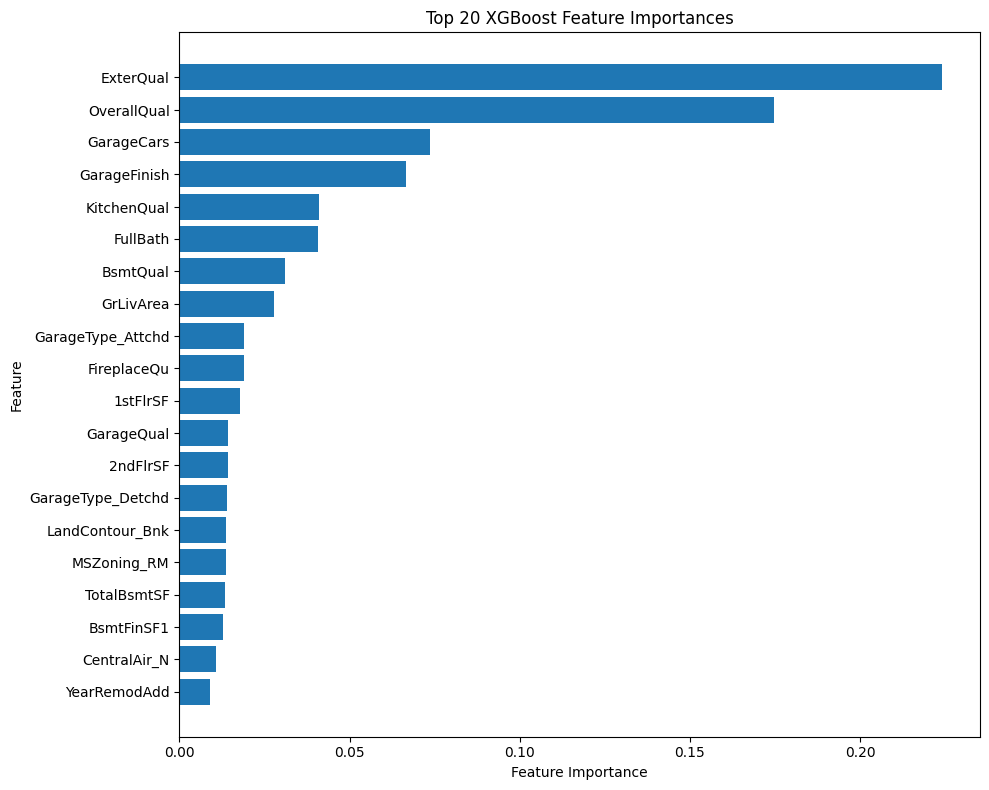

In [ ]:
top_20_features = feature_importance.head(20).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_20_features["Feature"],
    top_20_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

Les résultats de la feature importance confirment partiellement les observations de l’EDA. OverallQual, GrLivArea, les variables de qualité et certaines variables liées au garage apparaissent comme importantes pour le modèle. Cependant, l’ordre des variables n’est pas identique à celui obtenu avec les corrélations. Cela montre qu’une forte corrélation univariée avec SalePrice ne signifie pas nécessairement qu’une variable sera la plus importante pour un modèle comme XGBoost, qui exploite les interactions et les relations non linéaires entre plusieurs variables.


In [ ]:
feature_results = pd.DataFrame({
    "Model": [
        "XGBoost Baseline",
        "XGBoost + TotalPorchSF",
        "XGBoost + HouseAge",
        "XGBoost + RemodAge"
    ],
    "RMSE": [
        25685.9719,
        25343.3876,
        25497.8274,
        25467.4481
    ],
    "MAE": [
        16243.8428,
        16084.1572,
        16166.9365,
        16216.3818
    ],
    "R2": [
        0.913984,
        0.916263,
        0.915240,
        0.915442
    ]
})

feature_results

,Model,RMSE,MAE,R2
0,XGBoost Baseline,25685.9719,16243.8428,0.913984
1,XGBoost + TotalPorchSF,25343.3876,16084.1572,0.916263
2,XGBoost + HouseAge,25497.8274,16166.9365,0.915240
3,XGBoost + RemodAge,25467.4481,16216.3818,0.915442


## 13. Modèle final pédagogique

Choisir le modèle à partir des résultats précédents, le valider une dernière fois, puis l'entraîner sur toutes les données d'entraînement.

In [ ]:
X_final = X_total_porch.copy()

print("Final feature matrix shape:", X_final.shape)
print("Number of features:", X_final.shape[1])
print("Total missing values:", X_final.isnull().sum().sum())

Final feature matrix shape: (1460, 240)
Number of features: 240
Total missing values: 0


In [ ]:
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_final,
    y,
    test_size=0.2,
    random_state=42
)

xgb_final = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_final.fit(X_train_final, y_train_final)

y_pred_final = xgb_final.predict(X_val_final)

final_rmse = np.sqrt(
    mean_squared_error(y_val_final, y_pred_final)
)

final_mae = mean_absolute_error(
    y_val_final, y_pred_final
)

final_r2 = r2_score(
    y_val_final, y_pred_final
)

print("Final XGBoost Model + TotalPorchSF")
print("-----------------------------------")
print("RMSE:", final_rmse)
print("MAE :", final_mae)
print("R²  :", final_r2)

Final XGBoost Model + TotalPorchSF
-----------------------------------
RMSE: 25343.387618864217
MAE : 16084.1572265625
R²  : 0.9162633419036865


In [ ]:
xgb_final_full = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_final_full.fit(
    X_final,
    y
)

print("Final model trained on full training data.")
print("Training samples:", X_final.shape[0])
print("Features:", X_final.shape[1])

Final model trained on full training data.
Training samples: 1460
Features: 240


## 14. Préparation de `test.csv`

Appliquer exactement les transformations nécessaires sans utiliser les valeurs de `SalePrice` du test. Vérifier les dimensions, les colonnes, les valeurs manquantes et l'ordre des features.

In [ ]:
test_prep = test.copy()

print("Test shape:", test_prep.shape)
print("Missing values:", test_prep.isnull().sum().sum())

Test shape: (1459, 80)
Missing values: 7878


In [ ]:
test_missing = test_prep.isnull().sum().sort_values(ascending=False)

test_missing = test_missing[test_missing > 0]

print("Columns with missing values:")
print(test_missing)

print("\nTotal missing values:", test_missing.sum())

Columns with missing values:
PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageYrBlt       78
GarageCond        78
GarageFinish      78
GarageQual        78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
BsmtHalfBath       2
Utilities          2
Functional         2
BsmtFullBath       2
BsmtFinSF1         1
Exterior1st        1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
SaleType           1
KitchenQual        1
GarageCars         1
GarageArea         1
Exterior2nd        1
dtype: int64

Total missing values: 7878


In [ ]:
test_prep[
    ["PoolQC", "MiscFeature", "Alley", "Fence",
     "MasVnrType", "FireplaceQu",
     "GarageType", "GarageFinish", "GarageQual", "GarageCond",
     "BsmtQual", "BsmtCond", "BsmtExposure",
     "BsmtFinType1", "BsmtFinType2"]
] = test_prep[
    ["PoolQC", "MiscFeature", "Alley", "Fence",
     "MasVnrType", "FireplaceQu",
     "GarageType", "GarageFinish", "GarageQual", "GarageCond",
     "BsmtQual", "BsmtCond", "BsmtExposure",
     "BsmtFinType1", "BsmtFinType2"]
].fillna("None")

print("Remaining missing values:")
print(test_prep.isnull().sum().sort_values(ascending=False).head(20))

Remaining missing values:
LotFrontage     227
GarageYrBlt      78
MasVnrArea       15
MSZoning          4
BsmtFullBath      2
BsmtHalfBath      2
Utilities         2
Functional        2
Exterior1st       1
Exterior2nd       1
TotalBsmtSF       1
BsmtFinSF1        1
GarageCars        1
GarageArea        1
SaleType          1
KitchenQual       1
BsmtFinSF2        1
BsmtUnfSF         1
BldgType          0
Neighborhood      0
dtype: int64


In [ ]:
numeric_impute_cols = [
    "LotFrontage",
    "GarageYrBlt",
    "MasVnrArea",
    "BsmtFullBath",
    "BsmtHalfBath",
    "TotalBsmtSF",
    "BsmtFinSF1",
    "GarageCars",
    "GarageArea",
    "BsmtFinSF2",
    "BsmtUnfSF"
]

for col in numeric_impute_cols:
    test_prep[col] = test_prep[col].fillna(
        train[col].median()
    )

print("Remaining missing values:")
print(test_prep.isnull().sum().sort_values(ascending=False).head(20))

Remaining missing values:
MSZoning        4
Utilities       2
Functional      2
Exterior1st     1
Exterior2nd     1
KitchenQual     1
SaleType        1
MSSubClass      0
LotShape        0
LandContour     0
LotConfig       0
Id              0
LotArea         0
Street          0
Alley           0
LotFrontage     0
BldgType        0
Condition2      0
Condition1      0
Neighborhood    0
dtype: int64


In [ ]:
categorical_impute_cols = [
    "MSZoning",
    "Utilities",
    "Functional",
    "Exterior1st",
    "Exterior2nd",
    "KitchenQual",
    "SaleType"
]

for col in categorical_impute_cols:
    test_prep[col] = test_prep[col].fillna(
        train[col].mode()[0]
    )

print("Total missing values:", test_prep.isnull().sum().sum())

print("\nRemaining missing values:")
print(
    test_prep.isnull().sum()[
        test_prep.isnull().sum() > 0
    ]
)

Total missing values: 0

Remaining missing values:
Series([], dtype: int64)


In [ ]:
for col, mapping in ordinal_mappings.items():
    test_prep[col] = test_prep[col].map(mapping)

print("Remaining object columns:")
print(test_prep.select_dtypes(include="object").columns.tolist())

print("\nMissing values after ordinal encoding:")
print(test_prep.isnull().sum().sum())

Remaining object columns:
['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'PavedDrive', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']

Missing values after ordinal encoding:
0


In [ ]:
test_prep = pd.get_dummies(
    test_prep,
    columns=nominal_cols,
    drop_first=False,
    dtype=int
)

print("Test shape after encoding:", test_prep.shape)
print("Remaining object columns:", test_prep.select_dtypes(include="object").columns.tolist())

Test shape after encoding: (1459, 223)
Remaining object columns: []


In [ ]:
X_test_final = test_prep.reindex(
    columns=X_final.columns,
    fill_value=0
)

print("Final test shape:", X_test_final.shape)

print("Missing values:", X_test_final.isnull().sum().sum())

print(
    "Same columns as training:",
    list(X_test_final.columns) == list(X_final.columns)
)

Final test shape: (1459, 240)
Missing values: 0
Same columns as training: True


## 15. Predictions

Produire les 1459 prédictions et effectuer un sanity check : nombre, NaN, valeurs négatives, min, max, moyenne et médiane.

In [ ]:
y_test_pred = xgb_final_full.predict(X_test_final)

print("Number of predictions:", len(y_test_pred))
print("NaN predictions:", np.isnan(y_test_pred).sum())
print("Negative predictions:", (y_test_pred < 0).sum())

print("\nPrediction statistics:")
print("Min   :", y_test_pred.min())
print("Max   :", y_test_pred.max())
print("Mean  :", y_test_pred.mean())
print("Median:", np.median(y_test_pred))

Number of predictions: 1459
NaN predictions: 0
Negative predictions: 0

Prediction statistics:
Min   : 36035.855
Max   : 554036.56
Mean  : 177830.1
Median: 156182.64


## 16. Kaggle — seulement après la formation

Cette partie sera faite séparément. Le but est de comprendre le metric Kaggle, créer le fichier de submission et analyser le score obtenu.

**Important :** le score Kaggle ne remplace pas l'évaluation ML faite sur train/validation.

In [ ]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": y_test_pred
})

print("Submission shape:", submission.shape)
print("\nFirst 5 rows:")
print(submission.head())

Submission shape: (1459, 2)

First 5 rows:
     Id      SalePrice
0  1461  122977.640625
1  1462  158609.187500
2  1463  172517.062500
3  1464  184320.953125
4  1465  194469.218750


In [ ]:
submission.to_csv("submission.csv", index=False)

print("Submission file created successfully.")
print("File:", "submission.csv")

Submission file created successfully.
File: submission.csv


In [ ]:
submission_check = pd.read_csv("submission.csv")

print("Shape:", submission_check.shape)
print("\nColumns:", submission_check.columns.tolist())

print("\nMissing values:")
print(submission_check.isnull().sum())

print("\nNegative SalePrice:", (submission_check["SalePrice"] < 0).sum())

print("\nDuplicate Ids:", submission_check["Id"].duplicated().sum())

print("\nFirst 5 rows:")
print(submission_check.head())

print("\nLast 5 rows:")
print(submission_check.tail())

Shape: (1459, 2)

Columns: ['Id', 'SalePrice']

Missing values:
Id           0
SalePrice    0
dtype: int64

Negative SalePrice: 0

Duplicate Ids: 0

First 5 rows:
     Id  SalePrice
0  1461  122977.64
1  1462  158609.19
2  1463  172517.06
3  1464  184320.95
4  1465  194469.22

Last 5 rows:
        Id  SalePrice
1454  2915   82392.29
1455  2916   82186.55
1456  2917  159838.70
1457  2918  122085.70
1458  2919  220350.80


Section 17 — XGBoost avec log1p(SalePrice)


In [ ]:
# Section 17: Log-transform the target

y_log = np.log1p(y)

print("Original SalePrice:")
print(y.describe())

print("\nLog-transformed SalePrice:")
print(y_log.describe())

Original SalePrice:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Log-transformed SalePrice:
count    1460.000000
mean       12.024057
std         0.399449
min        10.460271
25%        11.775105
50%        12.001512
75%        12.273736
max        13.534474
Name: SalePrice, dtype: float64


In [ ]:
X_train_log, X_val_log, y_train_log, y_val_log = train_test_split(
    X_final,
    y_log,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train_log.shape)
print("X_val:", X_val_log.shape)
print("y_train:", y_train_log.shape)
print("y_val:", y_val_log.shape)

X_train: (1168, 240)
X_val: (292, 240)
y_train: (1168,)
y_val: (292,)


In [ ]:
xgb_log_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_log_model.fit(
    X_train_log,
    y_train_log
)

print("XGBoost log-target model trained successfully.")

XGBoost log-target model trained successfully.


In [ ]:
# Predict in log-space
y_val_log_pred = xgb_log_model.predict(X_val_log)

# Convert predictions back to original SalePrice scale
y_val_pred_log = np.expm1(y_val_log_pred)

print("First 5 log predictions:")
print(y_val_log_pred[:5])

print("\nFirst 5 predictions in original SalePrice:")
print(y_val_pred_log[:5])

First 5 log predictions:
[11.855999  12.71892   11.6515045 11.9041395 12.703429 ]

First 5 predictions in original SalePrice:
[140926.23 334006.84 114863.05 147876.5  328872.75]


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_squared_log_error
)

# RMSE
rmse_log = np.sqrt(
    mean_squared_error(y_val, y_val_pred_log)
)

# MAE
mae_log = mean_absolute_error(
    y_val, y_val_pred_log
)

# R²
r2_log = r2_score(
    y_val, y_val_pred_log
)

# RMSLE
rmsle_log = np.sqrt(
    mean_squared_log_error(y_val, y_val_pred_log)
)

print("XGBoost + log1p(SalePrice)")
print("--------------------------------")
print(f"RMSE  : {rmse_log:.4f}")
print(f"MAE   : {mae_log:.4f}")
print(f"R²    : {r2_log:.4f}")
print(f"RMSLE : {rmsle_log:.4f}")

XGBoost + log1p(SalePrice)
--------------------------------
RMSE  : 27164.7984
MAE   : 15899.6025
R²    : 0.9038
RMSLE : 0.1330


In [ ]:
# Train the final log-target model on all training data

xgb_log_final = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_log_final.fit(
    X_final,
    y_log
)

print("Final log-target model trained successfully.")
print("Training samples:", X_final.shape[0])
print("Features:", X_final.shape[1])

Final log-target model trained successfully.
Training samples: 1460
Features: 240


In [ ]:
# Predict test prices in log-space
y_test_log_pred = xgb_log_final.predict(X_test_final)

# Convert back to original SalePrice scale
y_test_pred_v2 = np.expm1(y_test_log_pred)

print("Number of predictions:", len(y_test_pred_v2))
print("NaN:", np.isnan(y_test_pred_v2).sum())
print("Negative:", (y_test_pred_v2 < 0).sum())
print("Min:", y_test_pred_v2.min())
print("Max:", y_test_pred_v2.max())
print("Mean:", y_test_pred_v2.mean())
print("Median:", np.median(y_test_pred_v2))

Number of predictions: 1459
NaN: 0
Negative: 0
Min: 43192.516
Max: 484533.22
Mean: 174698.53
Median: 154919.5


In [ ]:
submission_v2 = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": y_test_pred_v2
})

submission_v2.to_csv("submission_v2.csv", index=False)

print("Submission V2 created successfully.")
print("Shape:", submission_v2.shape)
print("\nFirst 5 rows:")
print(submission_v2.head())

Submission V2 created successfully.
Shape: (1459, 2)

First 5 rows:
     Id      SalePrice
0  1461  122354.664062
1  1462  155892.625000
2  1463  185601.750000
3  1464  185969.921875
4  1465  196743.468750


In [ ]:
submission_v2_check = pd.read_csv("submission_v2.csv")

print("Shape:", submission_v2_check.shape)
print("\nColumns:", submission_v2_check.columns.tolist())

print("\nMissing values:")
print(submission_v2_check.isnull().sum())

print("\nNegative SalePrice:", (submission_v2_check["SalePrice"] < 0).sum())

print("\nDuplicate Ids:", submission_v2_check["Id"].duplicated().sum())

print("\nFirst 5 rows:")
print(submission_v2_check.head())

print("\nLast 5 rows:")
print(submission_v2_check.tail())

Shape: (1459, 2)

Columns: ['Id', 'SalePrice']

Missing values:
Id           0
SalePrice    0
dtype: int64

Negative SalePrice: 0

Duplicate Ids: 0

First 5 rows:
     Id   SalePrice
0  1461  122354.664
1  1462  155892.620
2  1463  185601.750
3  1464  185969.920
4  1465  196743.470

Last 5 rows:
        Id  SalePrice
1454  2915   80353.99
1455  2916   77238.66
1456  2917  155750.72
1457  2918  121788.76
1458  2919  224485.19
